# P6 Bottleneck — notebook d’analyse amélioré

**Copie de travail P13, réalisée à partir du notebook P6.** Le déroulé historique est conservé pour assurer la continuité. Un chapitre P13 ajoute les contrôles reproductibles et compare les résultats aux exports de référence.


# Objectif, périmètre et lecture des données

Le notebook conserve les analyses utiles du P6 et ajoute des contrôles P13 reproductibles. Les données sont distinguées en cinq étapes : **A. sources** (`*_source`, jamais modifiées) ; **B. transformations techniques** (types, colonnes dérivées et jointures) ; **C. anomalies** (alertes avec valeur observée conservée) ; **D. décisions métier** (à confirmer par un référent) ; **E. vues d’analyse P6** (dont le filtre historique de marge, isolé dans `df_clean_analysis`).

Les cellules historiques ne corrigent plus les prix, les statuts ou les identifiants et ne dédupliquent plus automatiquement les SKU. Un filtrage nécessaire au rapprochement ou à une analyse est présenté comme une vue; la source demeure accessible. La branche `export_observed` du pipeline est une reproduction distincte des exports, pas une validation métier.


### Etape 1 - Importation des librairies et chargement des fichiers

#### 1.1 - Importation des librairies

In [1]:
#Importation de la librairie Pandas
import pandas as pd

In [2]:
#Importation de la librairie plotly express
import plotly.express as px

#### 1.2 - Chargements des fichiers

In [3]:
# A. Chargement et contrôle de disponibilité des sources.
# Les tables *_source sont des instantanés en lecture seule; les vues de travail sont des copies.
from pathlib import Path
import os, sys
import warnings
import numpy as np


cwd=Path.cwd().resolve()
P13_ROOT=next((p for p in (cwd,*cwd.parents) if (p/"src"/"pipeline.py").is_file()),None)
if P13_ROOT is None: raise FileNotFoundError("Ouvrez ce notebook depuis le dossier du projet P13.")
DATA_DIR=Path(os.environ.get("P13_DATA_DIR",str(P13_ROOT.parent/"Projet_bottleneck"/"Data"))).expanduser()
P6_OUTPUT_DIR=P13_ROOT/"outputs"/"notebook_p6_historique"
P13_OUTPUT_DIR=P13_ROOT/"outputs"/"notebook_p13"
P6_OUTPUT_DIR.mkdir(parents=True,exist_ok=True); P13_OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

# Filtrage ciblé de l'avertissement openpyxl.
warnings.filterwarnings(
    "ignore",
    message=r"Unknown extension is not supported and will be removed",
    category=UserWarning,
)
df_web_source=pd.read_excel(DATA_DIR/"web.xlsx")
df_erp_source=pd.read_excel(DATA_DIR/"erp.xlsx")
df_liaison_source=pd.read_excel(DATA_DIR/"liaison.xlsx")
df_final_reference=pd.read_excel(DATA_DIR/"df_final.xlsx")
df_clean_reference=pd.read_excel(DATA_DIR/"df_clean.xlsx")
df_web=df_web_source.copy(deep=True); df_erp=df_erp_source.copy(deep=True); df_liaison=df_liaison_source.copy(deep=True)


print("Sources chargées depuis le dossier de données configuré")
print(f"ERP {df_erp_source.shape} | liaison {df_liaison_source.shape} | Web {df_web_source.shape}")
print(f"Références df_final {df_final_reference.shape} | df_clean {df_clean_reference.shape}")

Sources chargées depuis le dossier de données configuré
ERP (825, 6) | liaison (825, 2) | Web (1513, 29)
Références df_final (714, 34) | df_clean (713, 35)


In [4]:
# P13 — sources → schéma → rapprochement → contrôles et alertes.

# Aucune correction métier n'est appliquée au profil raw.
sys.path.insert(0,str(P13_ROOT/"src"))
from importlib import import_module

build_pipeline = import_module("pipeline").build_pipeline
profiles={name:build_pipeline(DATA_DIR,vat_multiplier=1.2,correction_profile=name)
          for name in ("raw","notebook_code","export_observed")}

# Le jeu qualité reste distinct de la vue historique à marge positive.
df_quality, df_clean_analysis_pipeline, report_raw, alerts_raw = profiles["raw"]
df_reproduction, df_clean_historique_reproduction, report_reproduction, alerts_reproduction = profiles["export_observed"]
print("Contrôles schéma, clés, jointures et alertes exécutés avant les analyses P6.")
print("Profil sources contrôlées :",df_quality.shape,"| alertes ligne à ligne :",len(alerts_raw))
print("Profil de reproduction des exports :",df_reproduction.shape,"| vue historique :",df_clean_historique_reproduction.shape)


Contrôles schéma, clés, jointures et alertes exécutés avant les analyses P6.
Profil sources contrôlées : (714, 51) | alertes ligne à ligne : 40
Profil de reproduction des exports : (714, 51) | vue historique : (713, 51)


### Etape 2 - Analyse exploratoire des fichiers

#### 2.1 - Analyse exploratoire du fichier erp.xlsx

In [5]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [6]:
#Consulter le nombre de colonnes
df_erp.shape[1]
#Le nombre de valeurs présentes dans chacune des colonnes
df_erp.count()

product_id        825
onsale_web        825
price             825
stock_quantity    825
stock_status      825
purchase_price    825
dtype: int64

In [7]:
df_erp.dtypes

product_id          int64
onsale_web          int64
price             float64
stock_quantity      int64
stock_status       object
purchase_price    float64
dtype: object

In [8]:
#Afficher les 5 premières lignes de la table
df_erp.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [9]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp['product_id'].duplicated().sum()


np.int64(0)

In [10]:
#Afficher les valeurs distinctes de la colonne stock_status
df_erp['stock_status'].unique()
# Inspection des valeurs observées de stock_status; les divergences sont contrôlées séparément.



array(['instock', 'outofstock'], dtype=object)

# Le statut dérivé permet un contrôle de cohérence, mais sa règle métier n'est pas confirmée.
# Toute divergence est une alerte; la valeur source de stock_status est conservée.

In [11]:
# B. Vue technique calculée pour comparer stock_status à une règle simple du P6.

# Ne remplace pas stock_status et ne présume pas la signification des stocks négatifs.
df_erp["stock_status_2"] = np.where(df_erp["stock_quantity"] == 0,"outofstock","instock")
df_erp["anomaly_stock_status"] = df_erp["stock_status"].ne(df_erp["stock_status_2"])
df_alerts_stock_status = df_erp.loc[df_erp["anomaly_stock_status"], ["product_id","stock_quantity","stock_status","stock_status_2"]].copy()
df_alerts_stock_status["action"] = "À examiner; conserver le statut source"

In [12]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset


0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [13]:
# Synthèse descriptive des concordances et divergences, sans correction automatique.
coherentes = int(df_erp["stock_status"].eq(df_erp["stock_status_2"]).sum())
incoherentes = int(df_erp["stock_status"].ne(df_erp["stock_status_2"]).sum())
print("Statuts concordants :",coherentes,"| écarts à examiner :",incoherentes)


Statuts concordants : 821 | écarts à examiner : 4


Le contrôle compare le statut source à un statut calculé selon la convention historique « stock nul ⇒ outofstock, sinon instock ». Un écart est une alerte à interpréter avec le référent métier. Aucun statut n'est remplacé.

In [14]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
df_erp[df_erp["stock_status"] != df_erp["stock_status_2"]]

# Affichage des lignes ne correspondant pas au contrôle de statut calculé.

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,anomaly_stock_status
4,4039,1,46.0,3,outofstock,23.77,instock,True
398,4885,1,18.7,0,instock,9.66,outofstock,True
449,4973,0,10.0,-10,outofstock,4.96,instock,True
573,5700,1,44.5,-1,outofstock,22.30,instock,True


In [15]:
# Conserver stock_status d'origine. Les écarts sont disponibles dans df_alerts_stock_status.
df_erp.loc[df_erp["anomaly_stock_status"], ["product_id","stock_quantity","stock_status","stock_status_2"]]

,product_id,stock_quantity,stock_status,stock_status_2
4,4039,3,outofstock,instock
398,4885,0,instock,outofstock
449,4973,-10,outofstock,instock
573,5700,-1,outofstock,instock


#### 2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx

#### 2.1.1.1 - Analyse de la variable PRIX

In [16]:
###############
## LES PRIX  ##
###############

# Vérification des prix : valeurs manquantes, négatives ou nulles

# 1) Prix non renseignés
nb_non_renseignes = df_erp["price"].isna().sum()
print(f"Nombre d'articles avec un prix non renseigné : {nb_non_renseignes}")
print(df_erp[df_erp["price"].isna()][["product_id", "price"]])

# 2) Prix minimum et maximum
print(f"Prix minimum : {df_erp['price'].min()}")
print(f"Prix maximum : {df_erp['price'].max()}")

# 3) Prix négatifs
print("Prix négatifs :")
print(df_erp[df_erp["price"] < 0][["product_id", "price"]])

# 4) Prix nuls
print("Prix nuls :")
print(df_erp[df_erp["price"] == 0][["product_id", "price"]])

Nombre d'articles avec un prix non renseigné : 0
Empty DataFrame
Columns: [product_id, price]
Index: []
Prix minimum : -20.0
Prix maximum : 225.0
Prix négatifs :
     product_id  price
151        4233  -20.0
469        5017   -8.0
739        6594   -9.1
Prix nuls :
Empty DataFrame
Columns: [product_id, price]
Index: []


Les prix négatifs sont des anomalies à examiner; leur cause (retour, avoir, convention ou erreur) n'est pas déterminable ici. Les valeurs et product_id concernés restent inchangés dans la source et dans le rapport d'alertes. Aucun remplacement par NaN ou autre valeur n'est appliqué.

In [17]:
# Alerte de prix négatif, sans remplacer ni supprimer la valeur source.
df_erp["anomaly_price_negative"] = pd.to_numeric(df_erp["price"], errors="coerce").lt(0)
df_alerts_price = df_erp.loc[df_erp["anomaly_price_negative"], ["product_id","price"]].copy()
df_alerts_price["action"] = "À examiner; prix source conservé"
df_alerts_price

,product_id,price,action
151,4233,-20.0,À examiner; prix source conservé
469,5017,-8.0,À examiner; prix source conservé
739,6594,-9.1,À examiner; prix source conservé


#### 2.1.1.2 - Analyse de la variable STOCK

In [18]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print("Stock minimum :", df_erp["stock_quantity"].min())

#Afficher la quantité maximum de la colonne "stock_quantity"
print("Stock maximum :", df_erp["stock_quantity"].max())

# Contrôler les stocks négatifs; ils restent conservés et sont signalés.
print("Stocks inférieurs à 0 :")
print(df_erp[df_erp["stock_quantity"] < 0]["stock_quantity"])


Stock minimum : -10
Stock maximum : 145
Stocks inférieurs à 0 :
449   -10
573    -1
Name: stock_quantity, dtype: int64


#### 2.1.1.3 - Analyse de la variable ONSALE_WEB

In [19]:
# Valeurs observées dans la colonne onsale_web.
print("Valeurs uniques de la colonne onsale_web :", df_erp["onsale_web"].unique())

Valeurs uniques de la colonne onsale_web : [1 0]


La colonne onsale_web contient deux valeurs : 1 et 0.
1 signifie que le produit est disponible à la vente sur le site web, tandis que 0 indique qu’il n’est pas proposé en ligne. 
C’est un indicateur binaire utilisé par l’ERP pour gérer la visibilité des produits sur le site e‑commerce.

In [20]:
# Vue réduite aux colonnes utilisées dans cette exploration ERP.
colonnes_a_conserver = ["product_id", "price", "stock_quantity", "stock_status", "onsale_web"]
df_erp_reduit = df_erp[colonnes_a_conserver]
print("Colonnes conservées :", df_erp_reduit.columns.tolist())

Colonnes conservées : ['product_id', 'price', 'stock_quantity', 'stock_status', 'onsale_web']


In [21]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
df_erp.head()


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,anomaly_stock_status,anomaly_price_negative
0,3847,1,24.2,16,instock,12.88,instock,False,False
1,3849,1,34.3,10,instock,17.54,instock,False,False
2,3850,1,20.8,0,outofstock,10.64,outofstock,False,False
3,4032,1,14.1,26,instock,6.92,instock,False,False
4,4039,1,46.0,3,outofstock,23.77,instock,True,False


#### 2.1.1.4 - Analyse de la variable prix d'achat

In [22]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("Prix d'achat non renseignés :")
print(df_erp[df_erp["purchase_price"].isna()][["product_id", "purchase_price"]])

#Afficher le prix minimum de la colonne "purchase_price"
print("Prix d'achat minimum :", df_erp["purchase_price"].min())

#Afficher le prix maximum de la colonne "purchase_price"
print("Prix d'achat maximum :", df_erp["purchase_price"].max())



Prix d'achat non renseignés :
Empty DataFrame
Columns: [product_id, purchase_price]
Index: []
Prix d'achat minimum : 2.74
Prix d'achat maximum : 137.81


#### 2.2 - Analyse exploratoire du fichier web.xlsx
 

In [23]:
#Dimension du dataset
#Nombre d'observations
#Nombre de caractéristiques

# Analyse des dimensions du dataset df_web
nb_lignes, nb_colonnes = df_web.shape

print("=== Dimensions du dataset df_web ===")
print(f"Nombre d'observations : {nb_lignes}")
print(f"Nombre de caractéristiques : {nb_colonnes}")
print(f"Shape complet : {df_web.shape}")


=== Dimensions du dataset df_web ===
Nombre d'observations : 1513
Nombre de caractéristiques : 29
Shape complet : (1513, 29)


In [24]:

# Affichage complet du tableau (évite la troncature)
pd.set_option('display.max_rows', None)

# Total de valeurs non nulles + type de données
summary = pd.DataFrame({
    "total_values": df_web.count(),
    "dtype": df_web.dtypes
})

display(summary)



,total_values,dtype
sku,1428,object
virtual,1513,int64
downloadable,1513,int64
rating_count,1513,int64
average_rating,1430,float64
total_sales,1430,float64
tax_status,716,object
tax_class,0,float64
post_author,1430,float64
post_date,1430,datetime64[ns]


In [25]:
# Transformation technique limitée aux colonnes utilisées dans l'analyse P6.
# La table Web complète reste disponible dans df_web_source.
colonnes_a_supprimer = ["tax_class","post_content","post_password","post_content_filtered","ping_status","post_mime_type","post_excerpt"]
df_web = df_web.drop(columns=colonnes_a_supprimer, errors="ignore")
df_web.head()

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,...,post_status,comment_status,post_name,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,comment_count
0,11862,0,0,0,0.0,3.0,NaN,2.0,2018-02-12 13:46:23,2018-02-12 12:46:23,...,publish,closed,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,0.0
1,16057,0,0,0,0.0,5.0,NaN,2.0,2018-04-17 15:29:17,2018-04-17 13:29:17,...,publish,closed,pelle-sancerre-rouge-la-croix-au-garde-2017,2020-07-07 10:05:02,2020-07-07 08:05:02,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,0.0
2,14692,0,0,0,0.0,5.0,taxable,2.0,2019-03-19 10:06:47,2019-03-19 09:06:47,...,publish,closed,fonreaud-bordeaux-blanc-le-cygne-2016,2020-04-25 21:40:31,2020-04-25 19:40:31,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,0.0
3,16295,0,0,0,0.0,14.0,NaN,2.0,2018-02-15 14:05:06,2018-02-15 13:05:06,...,publish,closed,moulin-de-gassac-igp-pays-dherault-guilhem-ros...,2020-08-27 18:55:03,2020-08-27 16:55:03,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,0.0
4,15328,0,0,0,0.0,2.0,taxable,2.0,2019-03-27 18:05:09,2019-03-27 17:05:09,...,publish,closed,agnes-levet-cote-rotie-maestria-2017,2020-07-25 15:45:02,2020-07-25 13:45:02,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,0.0


In [26]:
# C. Profilage des SKU source : indicateurs exploratoires, aucune correction.
sku_source = df_web["sku"]
sku_text = sku_source.astype("string").str.strip()
df_web["anomaly_sku_missing"] = sku_source.isna() | sku_text.eq("")
df_web["anomaly_sku_atypical"] = sku_text.notna() & sku_text.ne("") & (~sku_text.str.fullmatch(r"\d+").fillna(False) | sku_text.str.len().lt(3) | sku_text.str.len().gt(20))
df_web["anomaly_sku_duplicate"] = sku_text.notna() & sku_text.duplicated(keep=False)
df_alerts_sku = df_web.loc[df_web["anomaly_sku_missing"] | df_web["anomaly_sku_atypical"] | df_web["anomaly_sku_duplicate"], ["post_type","post_title","sku","anomaly_sku_missing","anomaly_sku_atypical","anomaly_sku_duplicate"]].copy()
df_alerts_sku.insert(0,"web_source_row",df_alerts_sku.index)
df_alerts_sku["action"] = "À examiner; SKU source conservé"
display(df_alerts_sku.head(20))

,web_source_row,post_type,post_title,sku,anomaly_sku_missing,anomaly_sku_atypical,anomaly_sku_duplicate,action
0,0,attachment,Gilles Robin Hermitage Rouge 2012,11862,False,False,True,À examiner; SKU source conservé
1,1,attachment,Domaine Pellé Sancerre Rouge La Croix Au Garde...,16057,False,False,True,À examiner; SKU source conservé
2,2,product,Château Fonréaud Bordeaux Blanc Le Cygne 2016,14692,False,False,True,À examiner; SKU source conservé
3,3,attachment,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,16295,False,False,True,À examiner; SKU source conservé
4,4,product,Agnès Levet Côte Rôtie Maestria 2017,15328,False,False,True,À examiner; SKU source conservé
5,5,attachment,Château d'Arcole Saint-Emilion Grand Cru 2016,15471,False,False,True,À examiner; SKU source conservé
6,6,product,Château Turcaud Bordeaux Rouge Cuvée Majeure 2018,16515,False,False,True,À examiner; SKU source conservé
7,7,attachment,Domaine de La Tour Du Bon Bandol Blanc 2019,16246,False,False,True,À examiner; SKU source conservé
8,8,NaN,NaN,NaN,True,False,False,À examiner; SKU source conservé
9,9,attachment,Château Tour Haut-Caussan Médoc 2015,13572,False,False,True,À examiner; SKU source conservé


Les formats atypiques (par exemple les codes courts ou alphanumériques) sont signalés selon un profil exploratoire numérique. Aucune règle de codification métier n'étant validée, ils ne sont pas qualifiés d'invalides et aucune valeur de remplacement n'est inventée.

In [27]:
# Exemples de SKU repérés par le profilage; les valeurs source restent inchangées.
display(df_alerts_sku.loc[df_alerts_sku["anomaly_sku_atypical"], ["web_source_row","post_type","post_title","sku"]].head(20))


,web_source_row,post_type,post_title,sku
272,272,product,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,13127-1
458,458,attachment,Emile Boeckel Crémant Brut Blanc de Blancs,38
842,842,attachment,Bon cadeau de 25€,bon-cadeau-25-euros
964,964,product,Emile Boeckel Crémant Brut Blanc de Blancs,38
965,965,product,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,41
1117,1117,attachment,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,13127-1
1127,1127,attachment,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,41
1387,1387,product,Bon cadeau de 25€,bon-cadeau-25-euros


In [28]:
# Lignes où le SKU est manquant ou vide
nb_sans_sku = df_web[
    df_web["sku"].isna() | (df_web["sku"].astype(str).str.strip() == "")
].shape[0]

nb_sans_sku



85

In [28]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
sku_invalides = df_web[
    ~df_web["sku"].astype(str).str.fullmatch(r"\d+")
    & ~df_web["sku"].isna()
    & (df_web["sku"].astype(str).str.strip() != "")
]
sku_invalides.shape[0]
sku_invalides["sku"].unique()
sku_invalides.groupby("sku")["post_title"].nunique()



sku
13127-1                1
bon-cadeau-25-euros    1
Name: post_title, dtype: int64

Les SKU alphanumériques ou contenant un suffixe sont des références atypiques au regard du profil numérique exploré. Leur validité et leur sens (alias, déclinaison, bon cadeau ou erreur) doivent être confirmés. La valeur source est conservée; aucune correction n'est appliquée.

In [29]:
# Mesure du nombre de SKU répétés; les lignes concernées restent conservées.
df_web["sku"].duplicated().any()
df_web["sku"].duplicated().sum()
df_web["sku"].value_counts()[df_web["sku"].value_counts() > 1]


sku
11862                  2
16324                  2
3507                   2
14773                  2
15967                  2
15812                  2
16319                  2
16004                  2
15310                  2
16097                  2
14856                  2
15629                  2
1364                   2
15116                  2
14101                  2
14912                  2
15036                  2
16047                  2
14184                  2
14983                  2
16030                  2
8365                   2
15404                  2
15035                  2
15183                  2
15147                  2
16280                  2
14508                  2
15465                  2
3510                   2
14374                  2
15880                  2
13416                  2
15860                  2
16330                  2
11467                  2
11585                  2
14485                  2
16138                  2
19822                

Un SKU répété est signalé comme risque de clé. Le notebook conserve chaque ligne source et s'appuie sur `product_id` pour suivre les produits ERP. La nature d'une répétition (doublon technique, variante ou collision de référence) n'est pas déduite automatiquement.

In [30]:
# Vue des lignes sans SKU; la source Web complète reste disponible dans df_web_source.
df_sans_sku = df_web.loc[
    df_web["sku"].isna() | df_web["sku"].astype("string").str.strip().eq("")
].copy()
print("Lignes Web sans SKU :", len(df_sans_sku))
display(df_sans_sku.head())
df_sans_sku.info()


Lignes Web sans SKU : 85


,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,post_author,post_date,post_date_gmt,...,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,comment_count,anomaly_sku_missing,anomaly_sku_atypical,anomaly_sku_duplicate
8,NaN,0,0,0,NaN,NaN,NaN,NaN,NaT,NaT,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,True,False,False
20,NaN,0,0,0,NaN,NaN,NaN,NaN,NaT,NaT,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,True,False,False
30,NaN,0,0,0,NaN,NaN,NaN,NaN,NaT,NaT,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,True,False,False
37,NaN,0,0,0,NaN,NaN,NaN,NaN,NaT,NaT,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,True,False,False
41,NaN,0,0,0,NaN,NaN,NaN,NaN,NaT,NaT,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,True,False,False


<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    0 non-null      object        
 1   virtual                85 non-null     int64         
 2   downloadable           85 non-null     int64         
 3   rating_count           85 non-null     int64         
 4   average_rating         2 non-null      float64       
 5   total_sales            2 non-null      float64       
 6   tax_status             2 non-null      object        
 7   post_author            2 non-null      float64       
 8   post_date              2 non-null      datetime64[ns]
 9   post_date_gmt          2 non-null      datetime64[ns]
 10  product_type           2 non-null      object        
 11  post_title             2 non-null      object        
 12  post_status            2 non-null      object        
 13  comment_st

Le profilage trouve 85 lignes sans SKU tous types Web confondus, dont 2 lignes de type `product`. Les autres types ne sont pas des produits de catalogue dans le périmètre de la jointure. Les lignes restent dans `df_web_source`; seules des vues de rapprochement les écartent, et les produits sans SKU sont signalés.

In [31]:
# Aucune correction de SKU : conserver la valeur source et les indicateurs de la cellule de profilage.
# Les mappings historiques sont évalués séparément par le profil de reproduction P13.
df_alerts_sku[["web_source_row","post_type","post_title","sku","anomaly_sku_missing","anomaly_sku_atypical","anomaly_sku_duplicate"]].head(30)

,web_source_row,post_type,post_title,sku,anomaly_sku_missing,anomaly_sku_atypical,anomaly_sku_duplicate
0,0,attachment,Gilles Robin Hermitage Rouge 2012,11862,False,False,True
1,1,attachment,Domaine Pellé Sancerre Rouge La Croix Au Garde...,16057,False,False,True
2,2,product,Château Fonréaud Bordeaux Blanc Le Cygne 2016,14692,False,False,True
3,3,attachment,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,16295,False,False,True
4,4,product,Agnès Levet Côte Rôtie Maestria 2017,15328,False,False,True
5,5,attachment,Château d'Arcole Saint-Emilion Grand Cru 2016,15471,False,False,True
6,6,product,Château Turcaud Bordeaux Rouge Cuvée Majeure 2018,16515,False,False,True
7,7,attachment,Domaine de La Tour Du Bon Bandol Blanc 2019,16246,False,False,True
8,8,NaN,NaN,NaN,True,False,False
9,9,attachment,Château Tour Haut-Caussan Médoc 2015,13572,False,False,True


In [32]:
# Vue candidate pour le rapprochement; les autres lignes restent dans df_web / df_web_source.
df_web_products = df_web.loc[df_web["post_type"].eq("product")].copy()
df_web_products_missing_sku = df_web_products.loc[df_web_products["sku"].isna() | df_web_products["sku"].astype("string").str.strip().eq("")].copy()
df_web_products_joinable = df_web_products.loc[~df_web_products.index.isin(df_web_products_missing_sku.index)].copy()
print("Produits Web :", len(df_web_products), "| sans SKU :", len(df_web_products_missing_sku), "| candidats à la jointure :", len(df_web_products_joinable))

Produits Web : 716 | sans SKU : 2 | candidats à la jointure : 714


Les lignes sans SKU et les éventuelles répétitions sont conservées dans les tables sources et les alertes. `df_web_products_joinable` est une vue technique pour tenter le rapprochement, pas un référentiel corrigé ni dédupliqué.

#### 2.3 - Analyse exploratoire du fichier liaison.xlsx

In [33]:
#Dimension du dataset
#Nombre d'observations
print("Nombre d'observations :", df_liaison.shape[0])

#Nombre de caractéristiques
print("Nombre de caractéristiques :", df_liaison.shape[1])

Nombre d'observations : 825
Nombre de caractéristiques : 2


In [34]:
#Consulter le nombre de colonnes
print("Nombre de colonnes :", df_liaison.shape[1])
#La nature des données dans chacune des colonnes
print("Types de données dans chaque colonne :")
print(df_liaison.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Nombre de valeurs dans chaque colonne :")
print(df_liaison.count())


Nombre de colonnes : 2
Types de données dans chaque colonne :
id_web        object
product_id     int64
dtype: object
Nombre de valeurs dans chaque colonne :
id_web        734
product_id    825
dtype: int64


In [35]:
# Contrôle de l'unicité de product_id dans la source ERP.
print("Nombre de valeurs uniques dans 'product_id' :", df_liaison["product_id"].nunique())


Nombre de valeurs uniques dans 'product_id' : 825


In [36]:
# Contrôle de l'unicité de id_web dans la source liaison.
print("Nombre de valeurs uniques dans 'id_web' :", df_liaison["id_web"].nunique())


Nombre de valeurs uniques dans 'id_web' : 734


In [37]:
#affichage des 5 premières lignes du dataset
print("5 premières lignes du dataset :")
print(df_liaison.head(5))

5 premières lignes du dataset :
  id_web  product_id
0  15298        3847
1  15296        3849
2  15300        3850
3  19814        4032
4  19815        4039


In [38]:
# Vue des lignes de liaison dont product_id ou id_web est manquant.
df_sans_correspondance = df_liaison[df_liaison["product_id"].isna() | df_liaison["id_web"].isna()]
print(f"Nombre d'articles sans correspondance : {df_sans_correspondance.shape[0]}")
print("Détails des colonnes:")
print(df_sans_correspondance.info())


Nombre d'articles sans correspondance : 91
Détails des colonnes:
<class 'pandas.core.frame.DataFrame'>
Index: 91 entries, 19 to 821
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      0 non-null      object
 1   product_id  91 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 2.1+ KB
None


In [39]:
# Vue de contrôle des identifiants Web renseignés; df_liaison source reste complet.
df_liaison_id_web_renseignes = df_liaison.loc[df_liaison["id_web"].notna() & (df_liaison["id_web"].astype("string").str.strip() != "")].copy()
print("Liaisons avec id_web renseigné :", df_liaison_id_web_renseignes.shape[0],"/",len(df_liaison))
print("Les lignes sans id_web sont conservées dans df_liaison_source et df_alerts_id_web.")


Liaisons avec id_web renseigné : 734 / 825
Les lignes sans id_web sont conservées dans df_liaison_source et df_alerts_id_web.


In [40]:
# Contrôler les id_web sans les supprimer ni les remplacer.
id_web_source = df_liaison["id_web"].astype("string").str.strip()
df_liaison["anomaly_id_web_missing"] = df_liaison["id_web"].isna() | id_web_source.eq("")
df_liaison["anomaly_id_web_atypical"] = id_web_source.notna() & id_web_source.ne("") & ~id_web_source.str.fullmatch(r"\d{1,5}").fillna(False)
df_alerts_id_web = df_liaison.loc[df_liaison["anomaly_id_web_missing"] | df_liaison["anomaly_id_web_atypical"], ["product_id","id_web","anomaly_id_web_missing","anomaly_id_web_atypical"]].copy()
df_alerts_id_web["action"] = "À examiner; identifiant source conservé"
display(df_alerts_id_web.head(30))

,product_id,id_web,anomaly_id_web_missing,anomaly_id_web_atypical,action
19,4055,NaN,True,False,À examiner; identifiant source conservé
49,4090,NaN,True,False,À examiner; identifiant source conservé
50,4092,NaN,True,False,À examiner; identifiant source conservé
119,4195,NaN,True,False,À examiner; identifiant source conservé
131,4209,NaN,True,False,À examiner; identifiant source conservé
151,4233,NaN,True,False,À examiner; identifiant source conservé
184,4278,NaN,True,False,À examiner; identifiant source conservé
185,4279,NaN,True,False,À examiner; identifiant source conservé
234,4565,NaN,True,False,À examiner; identifiant source conservé
238,4577,NaN,True,False,À examiner; identifiant source conservé


### Etape 3 - Jonction des fichiers

#### Etape 3.1 - Jonction du fichier df_erp et df_liaison

In [41]:
#Fusion des fichiers df_erp et df_liaison
df_erp_liaison = df_erp.merge(df_liaison, on="product_id", how="left")
print("Dimensions du dataset fusionné :", df_erp_liaison.shape)

Dimensions du dataset fusionné : (825, 12)


In [42]:
# Lignes ERP sans id_web renseigné après la jointure ERP-liaison.
df_erp_liaison[df_erp_liaison["id_web"].isna()]
df_erp_liaison["id_web"].isna().sum()


np.int64(91)

#### Etape 3.2 - Jonction du fichier df_merge et df_web

In [43]:
# Jointure de travail sur les valeurs source, sans mapping ni déduplication de SKU.
# Le type product et la présence d'une clé sont les conditions de périmètre du rapprochement.
df_web_join = df_web_products_joinable.copy()
df_final_jointure_all = df_erp_liaison.merge(df_web_join, left_on="id_web", right_on="sku", how="left", suffixes=("", "_web"))
print("Jointure avec non-appariés conservés :", df_final_jointure_all.shape)


Jointure avec non-appariés conservés : (825, 37)


In [44]:
# Les non-appariés restent consultables et comptés; ils ne sont pas supprimés des sources.
df_final_unmatched = df_final_jointure_all.loc[df_final_jointure_all["sku"].isna()].copy()
print("Lignes ERP/liaison sans correspondance Web :",len(df_final_unmatched))
df_final_unmatched.head()

Lignes ERP/liaison sans correspondance Web : 111


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,anomaly_stock_status,anomaly_price_negative,id_web,...,post_modified,post_modified_gmt,post_parent,guid,menu_order,post_type,comment_count,anomaly_sku_missing,anomaly_sku_atypical,anomaly_sku_duplicate
19,4055,0,86.1,0,outofstock,37.88,outofstock,False,False,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN
49,4090,0,73.0,0,outofstock,33.79,outofstock,False,False,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN
50,4092,0,47.0,0,outofstock,25.25,outofstock,False,False,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN
119,4195,0,14.1,0,outofstock,7.36,outofstock,False,False,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN
131,4209,0,73.5,0,outofstock,33.01,outofstock,False,False,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN


In [45]:
# E. La jointure manuelle ci-dessus rend les non-appariés consultables.
# Les analyses P6 utilisent la sortie contrôlée raw du pipeline, sans mappings ni corrections métier.
df_p6_analysis = df_quality.copy(deep=True)
df_final = df_p6_analysis.copy(deep=True)
df_final_analysis = df_final.copy(deep=True)
print("Vérification des volumes : jointure manuelle",int(df_final_jointure_all["sku"].notna().sum()),"| df_quality raw",len(df_quality))
print("Produits en analyse P6 :",df_final.shape)


Vérification des volumes : jointure manuelle 714 | df_quality raw 714
Produits en analyse P6 : (714, 51)


### Etape 4 - Analyse univariée des prix

#### Etape 4.1 - Exploration par la visualisation de données

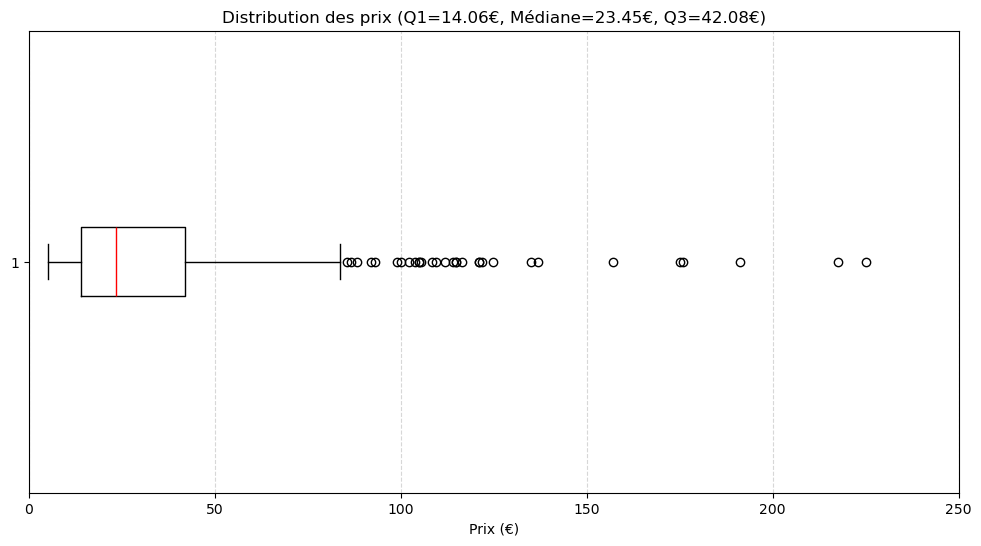

In [46]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
import matplotlib.pyplot as plt
q1 = df_final_analysis["price"].quantile(0.25)
median = df_final_analysis["price"].median()
q3 = df_final_analysis["price"].quantile(0.75)

plt.figure(figsize=(12, 6))
plt.boxplot(df_final_analysis["price"].dropna(), vert=False, medianprops={'color': 'red'})
plt.title(f"Distribution des prix (Q1={q1:.2f}€, Médiane={median:.2f}€, Q3={q3:.2f}€)")
plt.xlabel("Prix (€)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.xlim(0, 250)
plt.show()



In [47]:
#Autre méthode avec plotly express
import plotly.express as px

q1 = df_final_analysis["price"].quantile(0.25)
median = df_final_analysis["price"].median()
q3 = df_final_analysis["price"].quantile(0.75)

fig = px.box(
    df_final_analysis,
    x="price",
    points="outliers",
    title=f"Distribution des prix (Q1={q1:.2f}€, Médiane={median:.2f}€, Q3={q3:.2f}€)",
    color_discrete_sequence=["#4C78A8"]

)

fig.add_vline(x=median, line_dash="dash", line_color="red")
fig.update_layout(
    xaxis_title="Prix (€)",
    yaxis_title="",
    width=900,
    height=300
)

fig.update_xaxes(range=[0, 250])  # zoom sur la zone utile

fig.show()


La médiane observée est de 23,45 €. Le graphique montre une distribution asymétrique et des prix élevés par rapport au centre de la distribution. Ces constats statistiques ne permettent pas de qualifier les produits de premium ni de conclure à une anomalie métier.


#### Etape 4.2 - Exploration par l'utilisation de méthodes statistiques

#### Etape 4.2.1 - Identification par le Z-index

In [48]:
# Calcul de la moyenne et de l'écart-type
mean_price = df_final_analysis["price"].mean()
std_price = df_final_analysis["price"].std()

# Calcul du Z-score
df_final_analysis["z_score"] = (df_final_analysis["price"] - mean_price) / std_price

print(f"Moyenne du prix : {mean_price:.2f}€")
print(f"Écart-type du prix : {std_price:.2f}€")
print("Z-scores calculés et ajoutés au dataframe.")




Moyenne du prix : 32.33€
Écart-type du prix : 27.60€
Z-scores calculés et ajoutés au dataframe.


In [49]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
seuil = mean_price + 3 * std_price
seuil

# Affichage des articles dont le prix est supérieur au seuil
df_final_analysis[df_final_analysis["price"] > seuil][["price", "z_score","post_name"]]


,price,z_score,post_name
208,225.0,6.981591,champagne-egly-ouriet-grand-cru-millesime-2008
227,176.0,5.205993,cognac-frapin-vip-xo
230,157.0,4.517496,cognac-frapin-chateau-de-fontpinot-1989-20-ans
411,137.0,3.792762,domaine-des-croix-corton-charlemagne-grand-cru...
460,217.5,6.709816,david-duband-charmes-chambertin-grand-cru-2014
556,124.8,3.350674,domaine-weinbach-gewurztraminer-gc-furstentum-...
598,175.0,5.169756,camille-giroud-clos-de-vougeot-2016
635,191.3,5.760415,coteaux-champenois-egly-ouriet-ambonnay-rouge-...
651,122.0,3.249211,wemyss-malts-single-cask-scotch-whisky-choc-n-...
697,135.0,3.720288,champagne-gosset-celebris-vintage-2007


#### Etape 4.2.2 - Identification par l'intervalle interquartile

In [50]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
print("Statistiques descriptives de la colonne 'price' :")
print(df_final_analysis["price"].describe()) 



Statistiques descriptives de la colonne 'price' :
count    714.000000
mean      32.333683
std       27.596332
min        5.200000
25%       14.062500
50%       23.450000
75%       42.075000
max      225.000000
Name: price, dtype: float64


In [51]:
#Définir un seuil pour les articles "outliers" en prix
seuil_outliers = mean_price + 3 * std_price
print(f"Seuil pour les outliers : {seuil_outliers:.2f}€")



Seuil pour les outliers : 115.12€


In [52]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
nb_outliers = df_final_analysis[df_final_analysis["price"] > seuil_outliers].shape[0]
proportion_outliers = nb_outliers / df_final_analysis.shape[0] * 100
print(f"Nombre d'articles outliers : {nb_outliers}")
print(f"Proportion d'articles outliers : {proportion_outliers:.2f}%")


Nombre d'articles outliers : 13
Proportion d'articles outliers : 1.82%


In [53]:
# Valeurs de prix signalées par le seuil exploratoire Z-score; aucune qualification métier n'est déduite. 
outliers_df = df_final_analysis[df_final_analysis["z_score"] > 3][["sku","post_name", "price", "z_score"]]
outliers_df


,sku,post_name,price,z_score
208,15940,champagne-egly-ouriet-grand-cru-millesime-2008,225.0,6.981591
227,3510,cognac-frapin-vip-xo,176.0,5.205993
230,7819,cognac-frapin-chateau-de-fontpinot-1989-20-ans,157.0,4.517496
411,14220,domaine-des-croix-corton-charlemagne-grand-cru...,137.0,3.792762
460,14581,david-duband-charmes-chambertin-grand-cru-2014,217.5,6.709816
556,14915,domaine-weinbach-gewurztraminer-gc-furstentum-...,124.8,3.350674
598,15185,camille-giroud-clos-de-vougeot-2016,175.0,5.169756
635,14983,coteaux-champenois-egly-ouriet-ambonnay-rouge-...,191.3,5.760415
651,14775,wemyss-malts-single-cask-scotch-whisky-choc-n-...,122.0,3.249211
697,14923,champagne-gosset-celebris-vintage-2007,135.0,3.720288


Les prix repérés par Z-score sont des valeurs statistiques atypiques. La méthode ne permet pas de conclure qu'ils sont justifiés ou erronés; aucune ligne n'est supprimée et les prix observés restent disponibles pour revue métier.

### Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée

#### Etape 5.1 - Analyse des ventes en CA

In [54]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
# Vue de calcul du CA selon le périmètre historique stock_quantity >= 0.
# Les stocks négatifs restent présents dans df_final_analysis et dans les alertes.
df_ca = df_final_analysis.loc[df_final_analysis["stock_quantity"] >= 0].copy()
df_ca["ca_par_article"] = df_ca["price"] * df_ca["total_sales"] 

#Calculer la somme de la colonne "ca_par_article"
ca_total = df_ca["ca_par_article"].sum()
print(f"Le chiffre d'affaire total du site web est de {ca_total:.2f} euros.")

Le chiffre d'affaire total du site web est de 143324.10 euros.


Le calcul historique du chiffre d’affaires applique le périmètre stock_quantity ≥ 0 et donne 143 324,10 €. Cette sélection concerne uniquement cette mesure; les stocks négatifs restent conservés dans les données et signalés. La signification de -1 et l’exclusion éventuelle de ces produits nécessitent une validation métier.

In [55]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_ca_sorted = df_ca.sort_values(by="ca_par_article", ascending=False)  

#Réinitialiser l'index du dataset par un reset_index
df_ca_sorted = df_ca_sorted.reset_index(drop=True)

#Afficher les 20 premiers articles en CA
print("Top 20 des articles par chiffre d'affaires :")
print(df_ca_sorted[["sku", "post_name", "ca_par_article"]].head(20))

#Graphique en barre des 20 premiers articles avec plotly express dans l'ordre décroissant du CA et horizontal
top_20 = df_ca_sorted.head(20)

fig = px.bar(
    top_20,
    x="ca_par_article",
    y="post_name",
    orientation="h",
    title="Top 20 des articles par chiffre d'affaires",
    labels={
        "ca_par_article": "Chiffre d'affaires (€)",
        "post_name": "Article"
    },
    color="ca_par_article",
    color_continuous_scale=["#BFD7EA", "#4C78A8"]  # dégradé léger
)

fig.update_layout(
    height=650,
    width=900,
    yaxis=dict(
        categoryorder="total ascending",
        tickfont=dict(size=11)
    ),
    xaxis=dict(
        title_font=dict(size=14),
        tickfont=dict(size=12),
        showgrid=True,              # active les lignes verticales
        gridcolor="lightgrey",      # couleur douce
        gridwidth=0.5               # finesse des lignes
    ),
    title=dict(x=0.5, font=dict(size=22)),
    plot_bgcolor="white",
    paper_bgcolor="white",
    coloraxis_showscale=False,
    margin=dict(l=220, r=40, t=80, b=40)
)

fig.update_traces(
    marker_line_width=0.5,
    marker_line_color="white",
    hovertemplate="<b>%{y}</b><br>CA : %{x:,.0f} €<extra></extra>"
)

fig.show()






Top 20 des articles par chiffre d'affaires :
      sku                                          post_name  ca_par_article
0   15940     champagne-egly-ouriet-grand-cru-millesime-2008          2475.0
1   14983  coteaux-champenois-egly-ouriet-ambonnay-rouge-...          1147.8
2   12587          champagne-egly-ouriet-grand-cru-brut-rose          1113.0
3   15325                         agnes-levet-amethyste-2017           824.0
4   13996  domaine-des-comtes-lafon-volnay-1er-cru-santen...           805.0
5   13913  champagne-agrapart-fils-mineral-extra-brut-bla...           781.2
6   11602  domaine-des-comtes-lafon-volnay-1er-cru-santen...           735.0
7   15185                camille-giroud-clos-de-vougeot-2016           700.0
8   14923             champagne-gosset-celebris-vintage-2007           675.0
9   13914  champagne-agrapart-fils-lavizoise-grand-cru-20...           672.0
10  14596  david-duband-chambolle-musigny-1er-cru-les-sen...           633.6
11   7819     cognac-frapin-cha

In [56]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
df_ca_sorted["part_ca"] = df_ca_sorted["ca_par_article"] / ca_total

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_ca_sorted["ca_cumule"] = df_ca_sorted["part_ca"].cumsum()

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
# Inclure la première référence qui fait franchir le seuil de 80 %.
seuil_atteint = df_ca_sorted["ca_cumule"].ge(0.8)
nb_articles_80 = int(np.flatnonzero(seuil_atteint.to_numpy())[0] + 1) if seuil_atteint.any() else len(df_ca_sorted)
print(f"Nombre d'articles représentant 80% du CA : {nb_articles_80}")

#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
proportion_80 = nb_articles_80 / df_ca_sorted.shape[0] * 100
print(f"Proportion d'articles représentant 80% du CA : {proportion_80:.2f}%")

Nombre d'articles représentant 80% du CA : 434
Proportion d'articles représentant 80% du CA : 60.87%


Le calcul P6 nécessite 434 références, soit 60,87 % de la vue retenue, pour atteindre le seuil de 80 % du chiffre d’affaires. Le comptage inclut désormais la première référence qui fait franchir le seuil; l'ancien calcul excluait cette référence. Ce résultat décrit le lot et ne caractérise pas le positionnement commercial du catalogue.


#### Etape 5.2 - Analyse des ventes en quantité

In [57]:
#####################################
# Palmarès des articles en quantité #
#####################################

# Tri sur une vue dédiée; df_final reste dans son ordre de référence.
df_sales_sorted = df_final_analysis.sort_values(by="total_sales", ascending=False).copy()
print("Top 20 des articles par quantité vendue :")
print(df_sales_sorted[["id_web", "total_sales"]].head(20))

fig = px.bar(
    df_sales_sorted.head(20), y="post_name", x="total_sales", orientation="h",
    title="Top 20 des articles par quantité vendue",
    labels={"total_sales": "Quantité vendue", "post_name": "Article"},
    color="total_sales", color_continuous_scale=["#BFD7EA", "#4C78A8"]
)
fig.update_layout(
    height=650, width=850,
    yaxis=dict(categoryorder="total ascending", tickfont=dict(size=11)),
    xaxis=dict(title_font=dict(size=14), tickfont=dict(size=12), showgrid=True,
               gridcolor="lightgrey", gridwidth=0.5,
               tickvals=[0, 10, 15, 20, 25, 30, 35]),
    shapes=[dict(type="line", x0=35, x1=35, y0=-0.5, y1=19.5,
                 line=dict(color="lightgrey", width=1))],
    title=dict(x=0.5, font=dict(size=22)), plot_bgcolor="white",
    paper_bgcolor="white", coloraxis_showscale=False,
    margin=dict(l=220, r=40, t=80, b=40)
)
fig.update_traces(marker_line_width=0.5, marker_line_color="white",
                   hovertemplate="<b>%{y}</b><br>Quantité vendue : %{x}<extra></extra>")
fig.show()


Top 20 des articles par quantité vendue :
    id_web  total_sales
393  16148         36.0
126  15415         27.0
181  14864         24.0
344  14950         22.0
281  16525         22.0
700  14570         20.0
630  15325         20.0
140  15758         18.0
616  13572         17.0
606  15561         17.0
730  15705         17.0
605  14338         16.0
23   16275         16.0
390  16255         16.0
395  16149         16.0
113  16265         16.0
570  16304         16.0
62   16504         16.0
392  16274         15.0
468  14839         15.0


In [58]:
#############################
# Calculer le 20 / 80 en CA #
#############################


# Trier par quantité décroissante
df_q_sorted = df_final_analysis.sort_values(by="total_sales", ascending=False).copy()

# Calculer la part en quantité
df_q_sorted["part_quantite"] = df_q_sorted["total_sales"] / df_q_sorted["total_sales"].sum()

# Calculer le cumul
df_q_sorted["cumulative_part"] = df_q_sorted["part_quantite"].cumsum()

# Nombre d’articles nécessaires pour atteindre 80% des ventes
# Inclure la première référence qui fait franchir le seuil de 80 %.
seuil_atteint = df_q_sorted["cumulative_part"].ge(0.8)
num_articles = int(np.flatnonzero(seuil_atteint.to_numpy())[0] + 1) if seuil_atteint.any() else len(df_q_sorted)

# Proportion dans le catalogue
proportion = num_articles / len(df_q_sorted) * 100

print(f"Nombre d'articles représentant 80% des ventes en quantité : {num_articles}")
print(f"Proportion dans le catalogue : {proportion:.2f}%")


Nombre d'articles représentant 80% des ventes en quantité : 434
Proportion dans le catalogue : 60.78%


In [59]:
# Nombre de ventes totales
total_ventes = df_final_analysis["total_sales"].sum()
print(f"Nombre total de ventes : {total_ventes}")

Nombre total de ventes : 5751.0


Le calcul P6 nécessite 434 articles, soit 60,78 % des 714 produits appariés, pour atteindre le seuil de 80 % des ventes en quantité. Le comptage inclut désormais la première référence qui fait franchir le seuil; l'ancien calcul excluait cette référence. Ce résultat décrit le lot et ne permet pas d’inférer les causes commerciales de cette répartition.


#### Etape 5.3 - Analyse des stocks

In [60]:
######################################
# Calcul exploratoire des mois de stock
######################################
# Convention du POC : ratio défini uniquement si ventes strictement positives.
sales_for_months = pd.to_numeric(df_final_analysis["total_sales"], errors="coerce")
stock_for_months = pd.to_numeric(df_final_analysis["stock_quantity"], errors="coerce")
df_stock_sorted = df_final_analysis.assign(
    anomaly_mois_stock_indefini=sales_for_months.isna() | sales_for_months.le(0),
    mois_stock=stock_for_months.div(sales_for_months.where(sales_for_months.gt(0)))
).sort_values(by="mois_stock", ascending=False, na_position="last")

fig = px.bar(df_stock_sorted.head(20), y="post_title", x="mois_stock", orientation="h",
 title="Mois de stock calculables — 20 premières lignes",
 labels={"post_title":"Article","mois_stock":"Mois de stock"}, color="mois_stock",
 color_continuous_scale=["#BFD7EA","#4C78A8"])
fig.update_layout(height=650,width=850,yaxis=dict(categoryorder="total ascending",tickfont=dict(size=11)),
 xaxis=dict(title_font=dict(size=14),tickfont=dict(size=12),showgrid=True,gridcolor="lightgrey",gridwidth=0.5),
 title=dict(x=0.5,font=dict(size=22)),plot_bgcolor="white",paper_bgcolor="white",
 coloraxis_showscale=False,margin=dict(l=220,r=40,t=80,b=40))
fig.update_traces(marker_line_width=0.5,marker_line_color="white",
 hovertemplate="<b>%{y}</b><br>Mois de stock : %{x}<extra></extra>")
fig.show()


Le ratio historique stock_quantity / total_sales est exploratoire. La période de total_sales et l’interprétation du ratio en « mois » ne sont pas documentées dans les sources fournies. Les valeurs élevées ou non calculables sont signalées; elles ne suffisent pas à conclure à un surstock ni à recommander un déstockage.

In [61]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
df_final_analysis["Valorisation_stock_euros"] = df_final_analysis["stock_quantity"] * df_final_analysis["price"]

#Calculer la somme de la colonne "Valorisation_stock_euros"
valorisation_totale = df_final_analysis["Valorisation_stock_euros"].sum()
print(f"La valorisation totale des stocks en euros est de : {valorisation_totale:.2f} euros.")

La valorisation totale des stocks en euros est de : 494593.40 euros.


In [62]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
quantite_totale = df_final_analysis["stock_quantity"].sum()
print(f"La quantité totale de produits en stock est de : {quantite_totale} unités.")

La quantité totale de produits en stock est de : 16739 unités.


Dans la vue analysée, le prix moyen est de 32,13 €, la médiane du stock est de 22 unités, le stock total de 16 739 unités et sa valorisation calculée de 494 593,40 €. Ces indicateurs reprennent les formules P6 et ne démontrent pas, à eux seuls, le positionnement du catalogue ni une immobilisation financière.


#### Etape 5.4 - Analyse du taux de marge

In [63]:
##############################
# Analyse du taux de marge   #
##############################

# Création du prix HT
df_final_analysis["price_ht"] = df_final_analysis["price"] / 1.2

# Création du taux de marge
df_final_analysis["taux_marge"] = (df_final_analysis["price_ht"] - df_final_analysis["purchase_price"]) / df_final_analysis["price_ht"] * 100

# Affichage des marges min/max
print("Taux de marge minimum :", df_final_analysis["taux_marge"].min())
print("Taux de marge maximum :", df_final_analysis["taux_marge"].max())



Taux de marge minimum : -634.98814229249
Taux de marge maximum : 47.7568


In [64]:
#Affichage de la ligne avec un taux de marge inférieur à 0
df_final_analysis[df_final_analysis["taux_marge"] < 0][["sku", "post_name", "price", "purchase_price", "price_ht", "taux_marge"]]

,sku,post_name,price,purchase_price,price_ht,taux_marge
210,12589,champagne-egly-ouriet-grand-cru-brut-blanc-de-...,12.65,77.48,10.541667,-634.988142


In [65]:
# Garder df_final_analysis complet; le filtre historique devient une vue d'analyse distincte.
df_final_analysis["anomaly_margin_negative"] = pd.to_numeric(df_final_analysis["taux_marge"],errors="coerce").lt(0)
df_clean_analysis = df_final_analysis.loc[pd.to_numeric(df_final_analysis["taux_marge"],errors="coerce").gt(0)].copy()
print("df_final_analysis conservé :",len(df_final_analysis),"| vue historique taux_marge > 0 :",len(df_clean_analysis),"| marges négatives conservées :",int(df_final_analysis["anomaly_margin_negative"].sum()))

df_final_analysis conservé : 714 | vue historique taux_marge > 0 : 713 | marges négatives conservées : 1


In [66]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
df_marge_par_type = (
    df_clean_analysis
    .groupby("product_type")["taux_marge"]
    .mean()
    .reset_index()
)

#Graphique en barre du taux de marge moyen par type de produit avec plotly express
import plotly.express as px

# Tri décroissant
df_sorted = df_marge_par_type.sort_values(by="taux_marge", ascending=False)

# Palette personnalisée
palette = {
    "Champagne": "#FFD700",      
    "Cognac": "#8B4513",         
    "Gin": "#1E90FF",            
    "Huile d'olive": "#6B8E23",  
    "Vin": "#8B0000",           
    "Whisky": "#D2691E"          
}

# Graphique  
fig = px.bar(
    df_sorted,
    x="product_type",
    y="taux_marge",
    color="product_type",
    color_discrete_map=palette,
    title="Taux de marge moyen par type de produit",
    labels={
        "product_type": "Type de produit",
        "taux_marge": "Taux de marge moyen (%)"
    },
    hover_data={"taux_marge": ":.2f"},
    text="taux_marge"  
)


fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="inside"  
)

fig.update_layout(
    xaxis_title="Type de produit",
    yaxis_title="Taux de marge moyen (%)",
    showlegend=False
)

fig.show()





Le graphique présente le taux de marge moyen calculé par type de produit dans la vue df_clean_analysis. La formule et le coefficient TVA de 1,2 sont hérités du P6 et n'ont pas été validés par le référent métier; les écarts entre catégories doivent donc être lus comme des résultats descriptifs du POC.


#### Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price

Corrélations — reproduction P6 (zéros de ventes masqués sur la copie):


,stock_quantity,total_sales,price
stock_quantity,1.000000,0.448344,-0.104200
total_sales,0.448344,1.000000,-0.556778
price,-0.104200,-0.556778,1.000000


Corrélations — données source préservées:


,stock_quantity,total_sales,price
stock_quantity,1.000000,0.452579,-0.104200
total_sales,0.452579,1.000000,-0.519752
price,-0.104200,-0.519752,1.000000


Corrélations — export df_clean de référence:


,stock_quantity,total_sales,price
stock_quantity,1.000000,0.448344,-0.104200
total_sales,0.448344,1.000000,-0.556778
price,-0.104200,-0.556778,1.000000


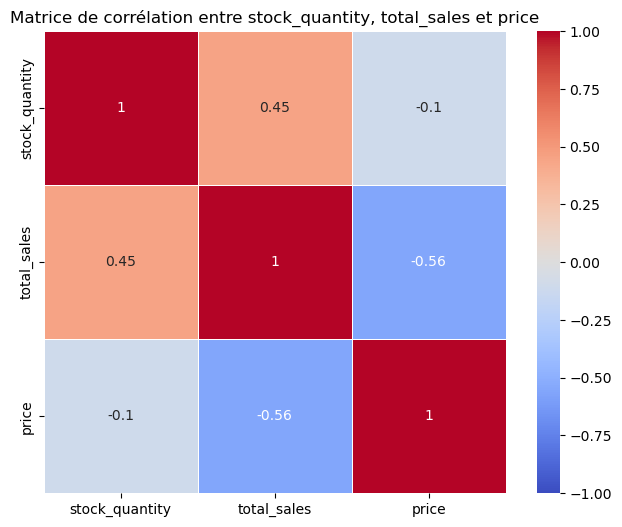

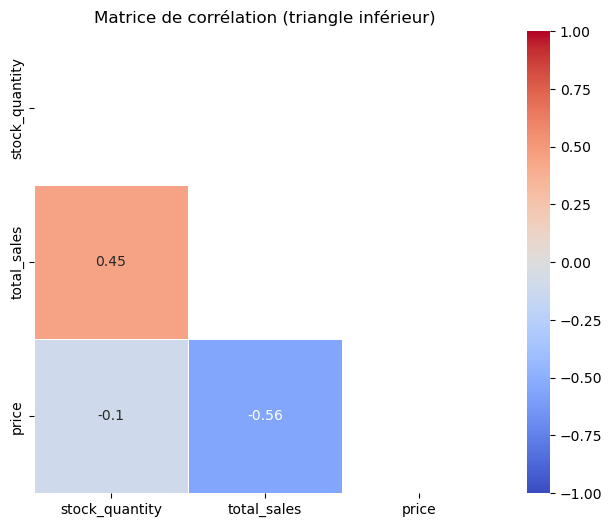

In [67]:
############################
# Analyse des corrélations #
############################

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Sélection des variables pertinentes
# Reproduction séparée du calcul historique : le P6 rendait total_sales nul manquant.
# df_clean_analysis / df_quality gardent les zéros sources inchangés.
df_clean_p6_reproduction = df_clean_analysis.copy(deep=True)
df_clean_p6_reproduction["total_sales"] = pd.to_numeric(df_clean_p6_reproduction["total_sales"],errors="coerce").mask(pd.to_numeric(df_clean_p6_reproduction["total_sales"],errors="coerce").eq(0))
variables_corr = df_clean_p6_reproduction[["stock_quantity", "total_sales", "price"]]
correlation_matrix = variables_corr.corr()
correlation_source_preserved = df_clean_analysis[["stock_quantity", "total_sales", "price"]].corr()
correlation_export_reference = df_clean_reference[["stock_quantity", "total_sales", "price"]].corr()
print("Corrélations — reproduction P6 (zéros de ventes masqués sur la copie):")
display(correlation_matrix)
print("Corrélations — données source préservées:")
display(correlation_source_preserved)
print("Corrélations — export df_clean de référence:")
display(correlation_export_reference)

# Heatmap complète
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)
plt.title("Matrice de corrélation entre stock_quantity, total_sales et price")
plt.show()

# Heatmap avec masque pour n'afficher que le triangle inférieur
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    mask=mask,
    linewidths=0.5,
    square=True
)
plt.title("Matrice de corrélation (triangle inférieur)")
plt.show()


Sur les données comparées, la corrélation ventes/prix est d’environ -0,56 et la corrélation ventes/stock d’environ 0,45. Ces coefficients décrivent des associations linéaires sur le lot; ils ne démontrent ni causalité ni adéquation d’une politique de réapprovisionnement.


#### Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel

In [68]:
# Export de la vue P6 historique, distincte de la jointure contrôlée.
df_clean_analysis.to_excel(P6_OUTPUT_DIR / "df_clean_analysis_historique.xlsx", index=False)
print("Vue analytique P6 historique :",df_clean_analysis.shape)
print("Les marges négatives restent disponibles dans df_final_analysis et le rapport df_alerts P13.")

Vue analytique P6 historique : (713, 52)
Les marges négatives restent disponibles dans df_final_analysis et le rapport df_alerts P13.


#### Étape 6.1 — Synthèse des alertes et points à valider


# Constats et alertes à examiner

Les constats décrivent le lot fourni; une alerte ne signifie pas qu'une donnée est erronée.

1. **Marge :** le produit 4355 / SKU `12589` affiche −634,99 % selon la formule P6 (prix HT 10,54 €, coût d'achat 77,48 €). Son exclusion de la vue d'analyse P6 `df_clean_analysis` évite de fausser les moyennes de ce lot. La ligne et la valeur restent dans `df_quality` et les alertes. La cause de l'écart et la formule doivent encore être vérifiées avec le métier.
2. **SKU :** deux produits Web ont un SKU manquant; des formats atypiques sont signalés selon un profil numérique exploratoire. Après normalisation observée dans la reproduction, le SKU `13127` est partagé par deux `product_id`. Les valeurs sources sont conservées.
3. **Rapprochement :** 91 lignes liaison ont `id_web` manquant et 111 lignes ERP/liaison n'ont pas de correspondance Web dans le profil observé. Les sources restent intactes; ces nombres se recouvrent en partie.
4. **Valeurs négatives :** 3 prix ERP, 2 stocks ERP et 2 ventes Web négatifs sont signalés. Aucune valeur n'est remplacée ou supprimée.
5. **Valeurs atypiques :** 13 prix dépassent le seuil exploratoire Z-score et 31 les bornes IQR; ces alertes statistiques ne sont pas des erreurs confirmées.
6. **Identifiants :** `product_id`, `id_web` et `sku` ont des rôles distincts dans les fichiers. Le rapprochement s'appuie sur les clés documentées; aucune colonne n'est supprimée au motif qu'elle serait redondante.

#### Etape 6.2 - Récapitulatif des corrections effectuées

# Récapitulatif des traitements de cette copie

- Les sources ERP, liaison et Web sont conservées dans des tables `*_source`; les analyses utilisent des copies ou des vues.
- Les colonnes non utilisées dans l'analyse P6 sont écartées de la vue de travail Web; le classeur source reste complet.
- Les identifiants et valeurs atypiques ne sont pas corrigés dans le profil contrôlé. Les variantes de mapping ne sont appliquées qu'aux profils de reproduction P13, avec les libellés sources présents dans les colonnes de traçabilité.
- Les produits sans clé Web ou sans SKU ne rejoignent pas la vue produit appariée, mais restent dans les sources, les alertes et/ou la vue des non-appariés.
- Les prix, stocks, ventes et marges négatifs sont conservés. Le filtre de marge positive est isolé dans une vue analytique historique.
- Les ventes nulles ou négatives restent inchangées; les mois de stock non calculables restent manquants et sont signalés.

#### Etape 6.3 - Recommandation d'améliorations

# Pistes d’amélioration à arbitrer

Les propositions ci-dessous ne constituent pas des règles approuvées :

1. Faire confirmer par le référent métier le dictionnaire des identifiants, la relation entre `product_id`, `id_web` et `sku`, et le SKU partagé `13127`.
2. Définir les actions attendues pour les prix, stocks, ventes et marges négatifs, sans remplacement automatique.
3. Valider la formule du taux de marge, le coefficient TVA 1,2 et le sens métier du ratio de stock avant d'utiliser ces indicateurs dans une décision.
4. Conserver l'exclusion analytique de la ligne à −634,99 % pour ce lot P6; confirmer avec le métier si le filtre général `taux_marge > 0` doit s'appliquer à d'autres lots. Garder les lignes exclues consultables.
5. Si le POC est repris, faire valider les seuils Z-score/IQR, attribuer un responsable des règles et vérifier le résultat sur plusieurs lots avant toute automatisation en entreprise.

# Partie P13 — pipeline contrôlé, reproduction des exports et validation

Dans les tableaux, **Sources contrôlées** correspond à `raw`, **Code historique P6** à `notebook_code` et **Exports reproduits** à `export_observed`. Ces noms décrivent les traitements, sans validation métier.

Le profil `raw` conserve les libellés SKU/id_web sources pour le jeu qualité joint. `export_observed` reproduit séparément les libellés et exports observés; `notebook_code` documente l'effet des mappings historiques. Aucune de ces sorties n'est une validation métier. Les vues exclues d'une jointure ou d'une analyse restent accessibles dans les sources ou dans `df_final_unmatched`.

Les règles métier encore à arbitrer sont les mappings d'identifiants, les SKU atypiques/dupliqués, les prix/stocks/ventes négatifs, les statuts de stock et le filtre historique de marge positive. Z-score et IQR sont des alertes exploratoires seulement.


Les écarts attendus avec les classeurs persistés sont quantifiés à la fin : 25 valeurs `total_sales` nulles dans `df_final` (24 dans `df_clean`) étaient enregistrées comme manquantes, alors que le jeu contrôlé garde le zéro source; le P6 les masquait seulement dans une copie pour reproduire ses corrélations et mois de stock. Les prix, coûts, stocks et marges du jeu apparié concordent par `product_id`. Les 3 statuts ERP discordants ne sont plus remplacés. Les deux libellés `sku` et `id_web` concernés ne sont normalisés que dans la reproduction `export_observed`. Le Z-score et les mois calculables sont gardés à pleine précision; les mois indéfinis restent manquants.


In [69]:
# Comparaison des profils P13 et des exports de référence.
profile_labels={"raw":"Sources contrôlées", "notebook_code":"Code historique P6", "export_observed":"Exports reproduits"}
profile_summary=pd.DataFrame([{"profil":profile_labels[name],"lignes_jointure":len(result[0]),"lignes_vue_marge_positive":len(result[1]),
 "alertes_pipeline":len(result[3])} for name,result in profiles.items()]).set_index("profil")
display(profile_summary)
def ids(frame): return set(frame["product_id"].dropna().astype(str))
def compare_ids(frame,reference): return ids(frame)==ids(reference)
comparison=pd.DataFrame([
 {"sortie":"Notebook P6 : jointure","lignes":len(df_final),"ids_vs_df_final":compare_ids(df_final,df_final_reference),"ids_vs_df_clean":None},
 {"sortie":"Sources contrôlées : jointure","lignes":len(df_quality),"ids_vs_df_final":compare_ids(df_quality,df_final_reference),"ids_vs_df_clean":None},
 {"sortie":"Sources contrôlées : marge > 0","lignes":len(df_clean_analysis_pipeline),"ids_vs_df_final":None,"ids_vs_df_clean":compare_ids(df_clean_analysis_pipeline,df_clean_reference)},
 {"sortie":"Exports reproduits : jointure","lignes":len(df_reproduction),"ids_vs_df_final":compare_ids(df_reproduction,df_final_reference),"ids_vs_df_clean":None},
 {"sortie":"Exports reproduits : marge > 0","lignes":len(df_clean_historique_reproduction),"ids_vs_df_final":None,"ids_vs_df_clean":compare_ids(df_clean_historique_reproduction,df_clean_reference)},
]).set_index("sortie")
display(comparison)

# Comparaison des valeurs métier, en complément des ensembles product_id.
def value_differences(actual,reference,column):
    a=actual.set_index("product_id").sort_index()[column]
    b=reference.set_index("product_id").sort_index()[column].reindex(a.index)
    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        av=a.astype(float).to_numpy(); bv=b.astype(float).to_numpy()
        exact=int((~np.isclose(av,bv,atol=1e-10,rtol=0,equal_nan=True)).sum())
        rounded=int((~np.isclose(np.round(av,2),np.round(bv,2),atol=1e-10,rtol=0,equal_nan=True)).sum())
    else:
        exact=int(a.astype("string").fillna("<NA>").ne(b.astype("string").fillna("<NA>")).sum()); rounded=exact
    return exact,rounded
value_rows=[]
for label,actual,reference in [("Sources contrôlées / df_final",df_quality,df_final_reference),
 ("Sources contrôlées (marge > 0) / df_clean",df_clean_analysis_pipeline,df_clean_reference),
 ("Exports reproduits / df_final",df_reproduction,df_final_reference),
 ("Exports reproduits (marge > 0) / df_clean",df_clean_historique_reproduction,df_clean_reference)]:
 for column in ("stock_status","id_web","sku","price","purchase_price","stock_quantity","total_sales","price_ht","taux_marge","Valorisation_stock_euros","mois_stock","z_score"):
  if column in actual.columns and column in reference.columns:
   exact,rounded=value_differences(actual,reference,column)
   value_rows.append({"comparaison":label,"colonne":column,"écarts_exacts":exact,"écarts_après_arrondi_2":rounded})
value_comparison=pd.DataFrame(value_rows)
display(value_comparison)


,lignes_jointure,lignes_vue_marge_positive,alertes_pipeline
profil,,,
Sources contrôlées,714,713,40
Code historique P6,713,712,40
Exports reproduits,714,713,40


,lignes,ids_vs_df_final,ids_vs_df_clean
sortie,,,
Notebook P6 : jointure,714,True,None
Sources contrôlées : jointure,714,True,None
pipeline raw marge > 0,713,None,True
Exports reproduits : jointure,714,True,None
pipeline export_observed marge > 0,713,None,True


,comparaison,colonne,écarts_exacts,écarts_après_arrondi_2
0,Sources contrôlées / df_final,stock_status,3,3
1,Sources contrôlées / df_final,id_web,2,2
2,Sources contrôlées / df_final,sku,2,2
3,Sources contrôlées / df_final,price,0,0
4,Sources contrôlées / df_final,purchase_price,0,0
5,Sources contrôlées / df_final,stock_quantity,0,0
6,Sources contrôlées / df_final,total_sales,25,25
7,Sources contrôlées / df_final,price_ht,0,0
8,Sources contrôlées / df_final,taux_marge,0,0
9,Sources contrôlées / df_final,Valorisation_stock_euros,0,0


## Décision, limites et conclusion

**Décision technique :** conserver les règles déterministes lisibles pour le POC. Garder Z-score et IQR en exploration sans exclusion de lignes. `raw` sert au contrôle avec identifiants source; `export_observed` est une vue distincte pour reproduire les exports; `notebook_code` mesure l'effet du code de correction historique. Great Expectations, Polars et dbt ne sont pas intégrés. Sur le lot P6, le produit 4355 / SKU `12589` (marge −634,99 %) est exclu de la seule vue analytique; sa valeur demeure dans les données contrôlées et les alertes.

**Limites :** un seul lot; règles métier et mappings non validés; durée avant/après non mesurée; aucune mise en production, ingestion planifiée, historisation, supervision ni écriture vers les sources. Le coefficient TVA 1,2 et les formules P6 n'ont pas été réaudités. Aucun gain de temps ou de qualité n'est revendiqué.

**Conclusion :** le POC vérifie la reproductibilité et documente les alertes sur les classeurs fournis. Les alertes ne prouvent pas une erreur. Les décisions métier restent ouvertes et le système n'est pas en production.


### Préparer le registre et la fonction d’alertes


In [70]:
# Validation P13 — synthèse de l'exécution et rapport conservant les valeurs observées
alert_records=[]
def add_alerts(frame,table,category,column,mask,id_column=None,sku_column=None):
    selected=frame.loc[mask.fillna(False)]
    for idx,row in selected.iterrows():
        alert_records.append({"source_table":table,"source_row":str(idx),"category":category,
          "product_id":row.get(id_column,pd.NA) if id_column else pd.NA,
          "sku_or_identifier_source":row.get(sku_column,pd.NA) if sku_column else pd.NA,
          "column":column,"value_observed":row.get(column,pd.NA),
          "action":"À examiner avec le référent métier; valeur source conservée"})


### Contrôler les sources ERP, liaison et Web


In [71]:
# Sources ERP, liaison et Web.
add_alerts(df_erp_source,"ERP","prix négatif","price",pd.to_numeric(df_erp_source["price"],errors="coerce").lt(0),"product_id")
add_alerts(df_erp_source,"ERP","stock négatif","stock_quantity",pd.to_numeric(df_erp_source["stock_quantity"],errors="coerce").lt(0),"product_id")
status_calc=np.where(pd.to_numeric(df_erp_source["stock_quantity"],errors="coerce").eq(0),"outofstock","instock")
add_alerts(df_erp_source.assign(_expected=status_calc),"ERP","écart statut de stock","stock_status",df_erp_source["stock_status"].astype("string").ne(pd.Series(status_calc,index=df_erp_source.index)),"product_id")
add_alerts(df_liaison_source,"liaison","id_web manquant","id_web",df_liaison_source["id_web"].isna()|df_liaison_source["id_web"].astype("string").str.strip().eq(""),"product_id","id_web")
web_prod=df_web_source.loc[df_web_source["post_type"].eq("product")].copy()
web_sku=web_prod["sku"].astype("string").str.strip()
add_alerts(web_prod,"Web","SKU produit manquant","sku",web_prod["sku"].isna()|web_sku.eq(""),None,"sku")
add_alerts(web_prod,"Web","SKU atypique (profil exploratoire numérique)","sku",web_sku.notna()&web_sku.ne("")&(~web_sku.str.fullmatch(r"\d+").fillna(False)|web_sku.str.len().lt(3)|web_sku.str.len().gt(20)),None,"sku")
add_alerts(web_prod,"Web","SKU produit dupliqué","sku",web_sku.notna()&web_sku.duplicated(keep=False),None,"sku")
add_alerts(df_web_source,"Web","ventes négatives","total_sales",pd.to_numeric(df_web_source["total_sales"],errors="coerce").lt(0),None,"sku")


### Contrôler la jointure, les anomalies et les valeurs atypiques


In [72]:
# Jointure contrôlée raw: valeurs de prix/stock/ventes et marges conservées.
add_alerts(df_reproduction,"reproduction export_observed","SKU partagé après normalisation","sku",df_reproduction["sku"].duplicated(keep=False),"product_id","sku_web_source")
# Les mappings de reproduction sont signalés avec le libellé source à côté du libellé observé.
if "sku_web_source" in df_reproduction:
    changed_sku=df_reproduction["sku_web_source"].astype("string").ne(df_reproduction["sku"].astype("string"))
    add_alerts(df_reproduction,"reproduction export_observed","SKU normalisé pour reproduction","sku",changed_sku,"product_id","sku_web_source")
if "id_web_source" in df_reproduction:
    changed_id=df_reproduction["id_web_source"].astype("string").ne(df_reproduction["id_web"].astype("string"))
    add_alerts(df_reproduction,"reproduction export_observed","id_web normalisé pour reproduction","id_web",changed_id,"product_id","id_web_source")
add_alerts(df_quality,"jointure raw","marge négative","taux_marge",pd.to_numeric(df_quality["taux_marge"],errors="coerce").lt(0),"product_id","sku_web_source")
add_alerts(df_quality,"jointure raw","mois de stock non calculable","total_sales",df_quality["flag_mois_stock_indefini"],"product_id","sku_web_source")
price=pd.to_numeric(df_quality["price"],errors="coerce"); z=(price-price.mean())/price.std(ddof=1)
q1,q3=price.quantile(.25),price.quantile(.75); spread=q3-q1
add_alerts(df_quality.assign(_z=z),"jointure raw","prix atypique Z-score > 3","_z",z.gt(3),"product_id","sku_web_source")
iqr_mask=price.lt(q1-1.5*spread)|price.gt(q3+1.5*spread)
add_alerts(df_quality.assign(_price=price),"jointure raw","prix atypique IQR exploratoire","_price",iqr_mask,"product_id","sku_web_source")


### Consolider les alertes et comparer les exports


In [73]:
# Non-appariés conservés dans la jointure gauche du notebook.
add_alerts(df_final_unmatched,"ERP-liaison/Web","absence de correspondance Web","id_web",df_final_unmatched["sku"].isna(),"product_id","id_web")
df_alerts=pd.DataFrame(alert_records,columns=["source_table","source_row","category","product_id","sku_or_identifier_source","column","value_observed","action"])
alert_counts=(df_alerts.groupby("category").size().rename("nombre").sort_values(ascending=False).to_frame())
display(alert_counts)


,nombre
category,
absence de correspondance Web,111
id_web manquant,91
prix atypique IQR exploratoire,31
mois de stock non calculable,25
prix atypique Z-score > 3,13
SKU atypique (profil exploratoire numérique),4
écart statut de stock,4
prix négatif,3
SKU normalisé pour reproduction,2


### Afficher la validation P13


In [74]:
validation_summary=pd.DataFrame([
 {"rubrique":"Sources chargées","résultat":f"ERP {df_erp_source.shape}; liaison {df_liaison_source.shape}; Web {df_web_source.shape}"},
 {"rubrique":"Contrôles exécutés","résultat":"schéma/colonnes pipeline; clés et jointures; prix, stocks, ventes, statut, SKU, marge, mois de stock, Z-score et IQR"},
 {"rubrique":"Corrélations P6","résultat":"reproduction historique = "+str(correlation_matrix.loc["total_sales",["price","stock_quantity"]].to_dict())+"; valeurs sources préservées = "+str(correlation_source_preserved.loc["total_sales",["price","stock_quantity"]].to_dict())},
 {"rubrique":"Alertes par catégorie","résultat":str(alert_counts["nombre"].to_dict())+" (catégories recouvrables; non dédupliquées en produits uniques)"},
 {"rubrique":"Comparaison exports","résultat":str(comparison.to_dict(orient="index"))+"; écarts de valeurs détaillés dans value_comparison"},
 {"rubrique":"Validation métier requise","résultat":"mappings et SKU atypiques/dupliqués; prix/stocks/ventes négatifs; statuts de stock; seuil statistique; filtre de marge > 0; mois de stock indéfinis"},
 {"rubrique":"Statut global du POC","résultat":"POC techniquement reproductible sur le lot fourni, mais non validé en production et nécessitant encore des validations métier."},
 {"rubrique":"Fichiers exportés","résultat":"outputs/notebook_p13/df_quality_raw.csv; df_alerts.csv; df_clean_analysis_p6_historique.csv; df_final_export_observed_reproduction.csv; df_clean_export_observed_reproduction.csv"},
])
display(validation_summary)


,rubrique,résultat
0,Sources chargées,"ERP (825, 6); liaison (825, 2); Web (1513, 29)"
1,Contrôles exécutés,schéma/colonnes pipeline; clés et jointures; p...
2,Corrélations P6,reproduction historique = {'price': -0.5567780...
3,Alertes par catégorie,"{'absence de correspondance Web': 111, 'id_web..."
4,Comparaison exports,"{'Notebook P6 : jointure': {'lignes': 714, '..."
5,Validation métier requise,mappings et SKU atypiques/dupliqués; prix/stoc...
6,Statut global du POC,POC techniquement reproductible sur le lot fou...
7,Fichiers exportés,outputs/notebook_p13/df_quality_raw.csv; df_al...


### Exporter les résultats du POC


In [75]:
# Exports dans un dossier P13 séparé des classeurs sources.
df_quality.to_csv(P13_OUTPUT_DIR/"df_quality_raw.csv",index=False,encoding="utf-8-sig")
df_alerts.to_csv(P13_OUTPUT_DIR/"df_alerts.csv",index=False,encoding="utf-8-sig")
df_clean_analysis.to_csv(P13_OUTPUT_DIR/"df_clean_analysis_p6_historique.csv",index=False,encoding="utf-8-sig")
df_reproduction.to_csv(P13_OUTPUT_DIR/"df_final_export_observed_reproduction.csv",index=False,encoding="utf-8-sig")
df_clean_historique_reproduction.to_csv(P13_OUTPUT_DIR/"df_clean_export_observed_reproduction.csv",index=False,encoding="utf-8-sig")
